# NLP Assignment 1: Training Word2Vec on Child Speech

In this assignment, you will:

1. **Implement** and **Train** a Word2Vec (CBOW) model on a child speech dataset (50%).  
2. **Explore** word similarity using the learned embeddings (code: 20%; discussion: 15%).  
3. **Visualise** embeddings in 2D using SVD (15%).

**We will randomly run 15 submissions. If any bug occurs during execution OR the results fall outside a reasonable reproducible range compared to the logged results, the submission will receive 0 mark for this assignment.**

## 0. Load and clean the text data

In this step, we load the text file `1000_cs.txt` and pre-process each line by:
- Removing punctuation and special characters;
- Removing line breaks;
- Converting all text to lowercase;

The cleaned text is stored in `clean_sentences`, which will be then used to build the vocabulary and data for training the CBOW model.


In [1]:
import re
from collections import Counter

def preprocess(sentence):
    sentence = re.sub('[^A-Za-z0-9]+', ' ', sentence)
    sentence = re.sub('\n', '', sentence)
    sentence = sentence.lower()
    return sentence

sentences = open("1000_cs.txt", "r").readlines()
clean_sentences = [preprocess(sentence) for sentence in sentences]

# clean_sentences

## 1. Filter out low-frequency tokens

Here, we replace words that appear less than a minimum frequency (default=2) with the special token `<unk>`.  

This helps:
- Reduce vocabulary size
- Deal with unseen words
- Make the training process more stable

The filtered sentences are stored in `filtered_sentences`.

In [2]:
from collections import Counter

def filter_low_freq_tokens(sentences, min_freq=2, unk_token="<unk>"):
    filtered_sentences = []
    all_tokens = " ".join(sentences).split()
    word_counts = Counter(all_tokens)
    for s in sentences:
        toks = s.split()
        toks = [w if word_counts[w] >= min_freq else unk_token for w in toks]
        filtered_sentences.append(" ".join(toks))
    return filtered_sentences

filtered_sentences = filter_low_freq_tokens(clean_sentences, min_freq=2, unk_token="<unk>")

## 2. Build the CBOW training data

We now build the vocabulary and create training samples for the CBOW model.
- `vocab`: the list of unique words in the corpus  
- `word_to_ix` / `ix_to_word`: mappings between words and their indices  
- For each word in a sentence, we take a fixed-size context window (default=2)
  and use the surrounding words as input and the center word as the target.

Each training sample has the form: `(context_words, target_word)`.
The resulting dataset is stored in `data`.

In [3]:
def build_cbow_data(sentences, window_size=2):
    words = " ".join(sentences).split()
    vocab = set(words)

    word_to_ix = {word: i for i, word in enumerate(vocab)}
    ix_to_word = {i: word for i, word in enumerate(vocab)}

    data = []
    for s in sentences:
        ws = s.split()
        for i in range(window_size, len(ws) - window_size):
            context = [ws[i - j - 1] for j in reversed(range(window_size))] + \
                      [ws[i + j + 1] for j in range(window_size)]
            target = ws[i]
            data.append((context, target))

    return vocab, word_to_ix, ix_to_word, data

vocab, word_to_ix, ix_to_word, data = build_cbow_data(filtered_sentences, window_size=2)

data 

[(['i', 'knew', 'knew', 'there'], 'i'),
 (['knew', 'i', 'there', 'was'], 'knew'),
 (['i', 'knew', 'was', 'no'], 'there'),
 (['knew', 'there', 'no', 'letters'], 'was'),
 (['there', 'was', 'letters', 'didn'], 'no'),
 (['was', 'no', 'didn', 't'], 'letters'),
 (['no', 'letters', 't', 'you'], 'didn'),
 (['i', '<unk>', 'the', 'first'], 'em'),
 (['<unk>', 'em', 'first', 'time'], 'the'),
 (['em', 'the', 'time', 'and'], 'first'),
 (['the', 'first', 'and', 'it'], 'time'),
 (['first', 'time', 'it', 'was'], 'and'),
 (['time', 'and', 'was', '<unk>'], 'it'),
 (['de', 'man', 'it', 'in'], 'made'),
 (['man', 'made', 'in', 'dere'], 'it'),
 (['made', 'it', 'dere', 'and'], 'in'),
 (['it', 'in', 'and', 'den'], 'dere'),
 (['in', 'dere', 'den', 'he'], 'and'),
 (['that', 'that', 's', 'not'], 'horsie'),
 (['that', 'horsie', 'not', 'very'], 's'),
 (['horsie', 's', 'very', 'well'], 'not'),
 (['s', 'not', 'well', 'lady'], 'very'),
 (['to', 'make', 'campfire', 'we'], 'a'),
 (['make', 'a', 'we', 'made'], 'campfire'

## 3. Implement the CBOW model

To make the training process cleaner and more reusable, we wrap the core functions (`forward`, `backward`, `update`) into a `CBOW` class.

This helps:
- Keep model logic and training logic separate
- Make the code easier to read and maintain
- Allow easy extension (e.g., negative sampling or Skip-gram)

Please complete the functions in the below code based on the pseudo-code in the course slide.

In [4]:
import numpy as np

class CBOW:
    def __init__(self, vocab_size, embed_dim=100, lr=0.01):
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim
        self.lr = lr
        self.W_in = np.random.uniform(-0.01, 0.01, (vocab_size, embed_dim)).astype(np.float32)
        self.W_out = np.random.uniform(-0.01, 0.01, (embed_dim, vocab_size)).astype(np.float32)

    def log_softmax(self, x):
        x = x - np.max(x, axis=-1, keepdims=True)
        return x - np.log(np.exp(x).sum(axis=-1, keepdims=True))

    def forward(self, context_idxs):
        # forward is supplied with a numpy array of the index of each context word, according to our earlier vocab finding
        h = self.W_in[context_idxs].mean(axis=0, keepdims=True)

        # Get the similarity of the context vector with the surrounding vectors. 
        logits = h @ self.W_out
        log_probs = self.log_softmax(logits)

        return h, logits, log_probs

    def nll_loss(self, log_probs, target_idxs):
        return -log_probs[np.arange(len(target_idxs)), target_idxs].mean()

    def backward(self, preds, target_idxs, context_len):
        # backwards is supplied with the output of forwards, the actual solution, and the length of the context. 
        h, _, log_probs = preds

        dLogits = np.exp(log_probs)
        dLogits[0, target_idxs] -= 1.0  

        dW_out = h.T @ dLogits
        dh_each = dLogits @ self.W_out.T
        dh_each /= context_len

        return dW_out, dh_each

    def update(self, context_idxs, dW_out, dh_each):
        self.W_out -= self.lr * dW_out
        for i in context_idxs:
            self.W_in[i] -= self.lr * dh_each[0]

    def train_one_epoch(self, data):
        losses = []
        for context, target in data:
            context_idxs = np.array([word_to_ix[w] for w in context], dtype=np.int64)
            target_idxs = np.array([word_to_ix[target]], dtype=np.int64)

            preds = self.forward(context_idxs)
            loss = self.nll_loss(preds[-1], target_idxs)
            losses.append(loss)

            dW_out, dh_each = self.backward(preds, target_idxs, len(context_idxs))
            self.update(context_idxs, dW_out, dh_each)
        return np.mean(losses)

## 4. Model Training and Loss Visualisation

We now train the CBOW model for 30 epochs.  
For each epoch, we record the average negative log-likelihood loss and compute the perplexity.
After training, we plot the loss curve to observe the learning trend.

Epoch 1/50 | Avg loss: 6.6607 | PPL: 781.07
Epoch 2/50 | Avg loss: 6.4871 | PPL: 656.62
Epoch 3/50 | Avg loss: 5.8081 | PPL: 332.99
Epoch 4/50 | Avg loss: 5.4985 | PPL: 244.31
Epoch 5/50 | Avg loss: 5.3798 | PPL: 216.99
Epoch 6/50 | Avg loss: 5.3059 | PPL: 201.53
Epoch 7/50 | Avg loss: 5.2350 | PPL: 187.73
Epoch 8/50 | Avg loss: 5.1713 | PPL: 176.14
Epoch 9/50 | Avg loss: 5.1193 | PPL: 167.21
Epoch 10/50 | Avg loss: 5.0725 | PPL: 159.57
Epoch 11/50 | Avg loss: 5.0262 | PPL: 152.35
Epoch 12/50 | Avg loss: 4.9789 | PPL: 145.31
Epoch 13/50 | Avg loss: 4.9306 | PPL: 138.47
Epoch 14/50 | Avg loss: 4.8819 | PPL: 131.87
Epoch 15/50 | Avg loss: 4.8326 | PPL: 125.54
Epoch 16/50 | Avg loss: 4.7830 | PPL: 119.46
Epoch 17/50 | Avg loss: 4.7333 | PPL: 113.67
Epoch 18/50 | Avg loss: 4.6836 | PPL: 108.16
Epoch 19/50 | Avg loss: 4.6344 | PPL: 102.96
Epoch 20/50 | Avg loss: 4.5859 | PPL: 98.09
Epoch 21/50 | Avg loss: 4.5385 | PPL: 93.55
Epoch 22/50 | Avg loss: 4.4923 | PPL: 89.33
Epoch 23/50 | Avg loss

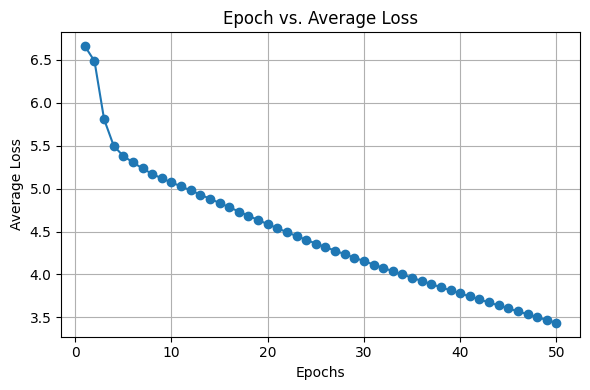

In [5]:
import numpy as np
import matplotlib.pyplot as plt

epoch_num = 50
epoch_losses = [] 

model = CBOW(vocab_size=len(vocab), embed_dim=100, lr=0.02) 

for epoch in range(epoch_num):
    avg_loss = model.train_one_epoch(data)
    ppl = np.exp(avg_loss)
    epoch_losses.append(float(avg_loss))   
    print(f"Epoch {epoch+1}/{epoch_num} | Avg loss: {avg_loss:.4f} | PPL: {ppl:.2f}")

epochs = np.arange(1, epoch_num + 1)

plt.figure(figsize=(6,4))
plt.title('Epoch vs. Average Loss')
plt.plot(epochs, epoch_losses, marker='o')  
plt.xlabel('Epochs')
plt.ylabel('Average Loss')
plt.grid(True)
plt.tight_layout()
plt.show()


## 5. Nearest neighbors (cosine similarity)

We retrieve semantically similar words by nearest neighbors in the embedding space.
Given a word and the `k` parameter, the function `topk_neighbors` will return a list of top k similar words.


In [6]:
import numpy as np

def cosine_similarity(v1, v2):
    # input: 2 vectors
    return (v1 @ v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))

def topk_neighbors(word, k, model, word_to_ix, ix_to_word):
    # Please write your code here

    input_idx = word_to_ix[word]
    input_embedding = model.W_in[input_idx]

    similarity = [(cosine_similarity(input_embedding, word), i) for i, word in enumerate(model.W_in) if i != input_idx]
    topK = sorted(similarity, reverse=True)[:k]

    return [(ix_to_word[i], float(s)) for s, i in topK]

k = 10
words = ['daddy', 'mummy', 'want', 'water', 'cat']
for word in words:
    print(topk_neighbors(word, k, model, word_to_ix, ix_to_word))

[('let', 0.6210566759109497), ('mommy', 0.5976036190986633), ('own', 0.5895737409591675), ('will', 0.5816179513931274), ('shlom', 0.5729993581771851), ('what', 0.5465053915977478), ('much', 0.5452666878700256), ('your', 0.5399200916290283), ('help', 0.5379694104194641), ('check', 0.5170636773109436)]
[('nothing', 0.7289445996284485), ('deir', 0.7280927896499634), ('head', 0.688190221786499), ('dere', 0.6782675981521606), ('shoes', 0.6778984665870667), ('ya', 0.6751008629798889), ('purse', 0.6728543639183044), ('glue', 0.6646483540534973), ('middle', 0.6631069779396057), ('problems', 0.6571036577224731)]
[('biscuit', 0.6184585690498352), ('could', 0.6096562147140503), ('buy', 0.6051833033561707), ('paper', 0.5995496511459351), ('wants', 0.5869747400283813), ('kiss', 0.5838232040405273), ('used', 0.581622838973999), ('draw', 0.570792555809021), ('eated', 0.5689120292663574), ('show', 0.5661110281944275)]
[('things', 0.569860577583313), ('hospital', 0.566175103187561), ('preschool', 0.564

### Discussion 

Please discuss the results of the similarity calculation with a top_k of 10, using five words: `daddy`, `mummy`, `want`, `water`, `cat` (200 words max).

### Discussion response: 

The neighbours suggest that we captured syntactic rather than semantic similarity. `want`'s neighbours are mostly verbs (i.e. `buy`, `kiss`), and `water`'s neighbours are mostly nouns (i.e. `hospital`, `garage`). This is expected since CBOW gives words similar embeddings if they fill similar position in the context window. This is reinforced by evidence of `water` being used as nouns in the dataset, rather than as verbs. The short context window of 5 used likely explains the syntactic similarity being highlighted over the semantic meaning.

There has been some limited success in capturing semantic meaning. `daddy`'s second closest word is `mommy` (0.597), consistent with both meaning parents. This is not the case for the variant `mummy`, which appears only 4 times in the dataset, versus 30 for `mommy`. This embedding may be undertrained, and its neighbours (`dier`, `glue`) looking like noise is further evidence for this. The same is true for `cat`, which only appears 7 times. 

Some noise may also be the result of non-standard words in the child langauge corpus. Further, the embeddings dimensionality is large given the size of the dataset - perhaps more data, wider windows and a lower dimensionality for the embedding might yield better results.

## 6. Visualise embeddings with SVD (PCA)

We now visualise the high-dimensional word embeddings into a 2D space using Singular Value Decomposition (SVD). 

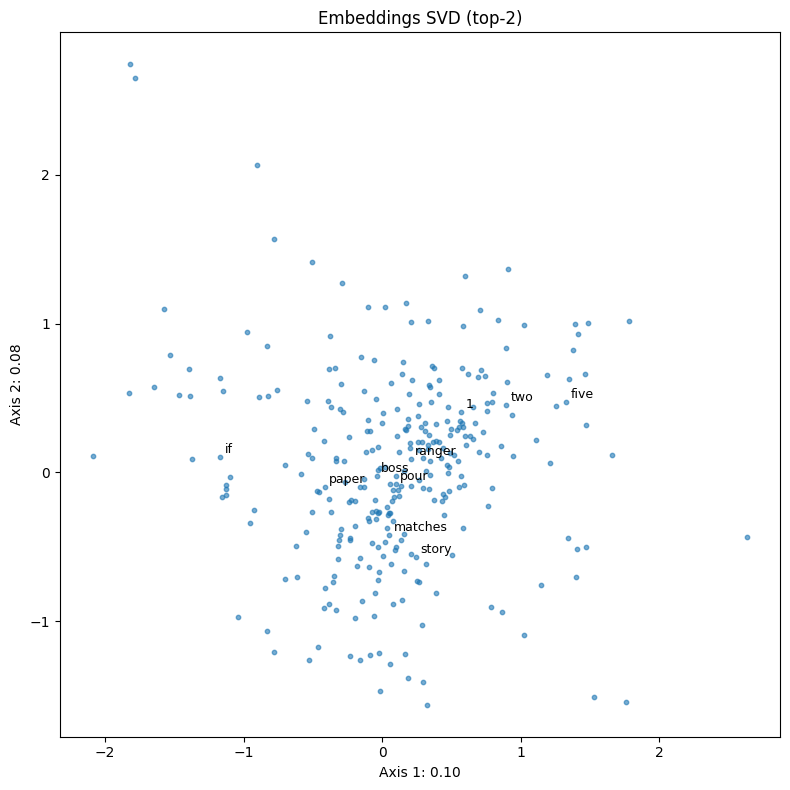

In [7]:
import numpy as np
import matplotlib.pyplot as plt

def plot_embeddings_svd2_simple(
    model,
    ix_to_word,
    max_points=300,
    annotate_k=10,
    random_state=42,
    title="Embeddings SVD (top-2)"
):
    n = min(max_points, model.vocab_size)
    sampled_idx = np.random.default_rng(random_state).choice(model.vocab_size, size=n, replace=False)

    X = model.W_in - model.W_in.mean(axis=0, keepdims=True)

    # note that svd alr gives the descending order, so we can just take the top 2 directions
    U, S, Vt = np.linalg.svd(X, full_matrices=False)
    coords = X[sampled_idx] @ Vt[:2].T 

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.scatter(coords[:, 0], coords[:, 1], s=10, alpha=0.6)

    for j in range(min(annotate_k, n)):
        word = ix_to_word[int(sampled_idx[j])]
        ax.annotate(word, coords[j], fontsize=9, xytext=(3, 3), textcoords="offset points")

    explained_var = (S**2 / np.sum(S**2))[:2]

    ax.set_xlabel(f"Axis 1: {explained_var[0]:.2f}")
    ax.set_ylabel(f"Axis 2: {explained_var[1]:.2f}")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

    return coords, explained_var, sampled_idx

coords, explained_var, idx = plot_embeddings_svd2_simple(
    ix_to_word=ix_to_word,
    model=model,              
    max_points=300,
    annotate_k=10,
    random_state=42
)